In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Plot settings
sns.set_theme(style="whitegrid")

# Load cleaned dataset
df = pd.read_csv("../data/cleaned/nepal_supermarket_sales_cleaned.csv")

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (235000, 14)


In [2]:
print("Total Sales:", df["Weekly_Sales"].sum())
print("Average Weekly Sales:", df["Weekly_Sales"].mean())
print("Median Weekly Sales:", df["Weekly_Sales"].median())
print("Highest Weekly Sales:", df["Weekly_Sales"].max())
print("Lowest Weekly Sales:", df["Weekly_Sales"].min())

Total Sales: 1585148366.9399996
Average Weekly Sales: 6745.312199744679
Median Weekly Sales: 6295.745
Highest Weekly Sales: 26240.98
Lowest Weekly Sales: 2164.72


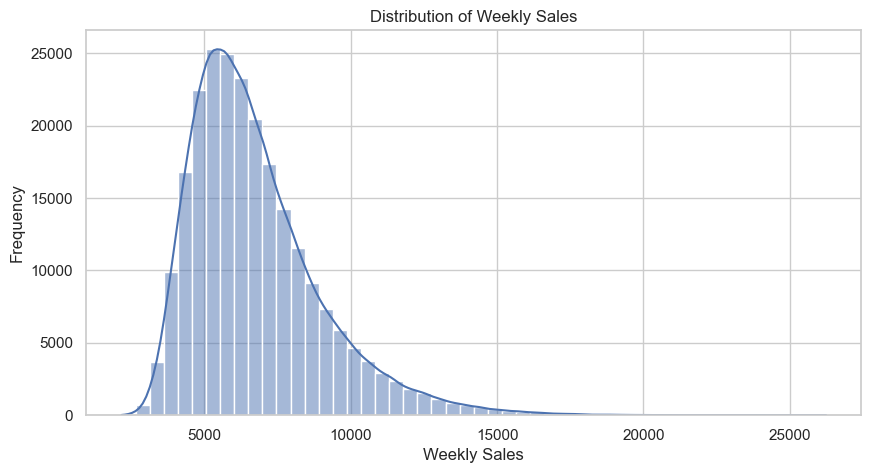

In [3]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Weekly_Sales"],
    bins=50,
    kde=True
)

plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")

plt.show()

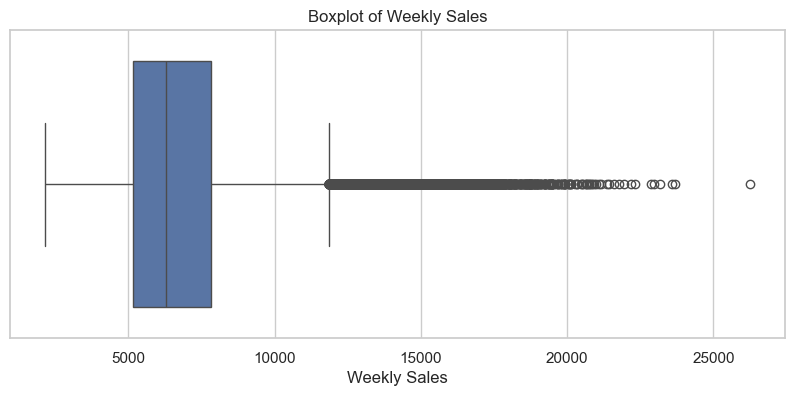

In [4]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Weekly_Sales"])

plt.title("Boxplot of Weekly Sales")
plt.xlabel("Weekly Sales")

plt.show()

In [6]:
yearly_sales = (
    df.groupby(df["Date"].dt.year)["Weekly_Sales"]
      .sum()
)

print(yearly_sales)

Date
2016   162407420.99
2017   168576755.13
2018   169066979.76
2019   171917862.14
2020   175510181.04
2021   178546413.04
2022   182017055.49
2023   188876965.82
2024   188228733.53
Name: Weekly_Sales, dtype: float64


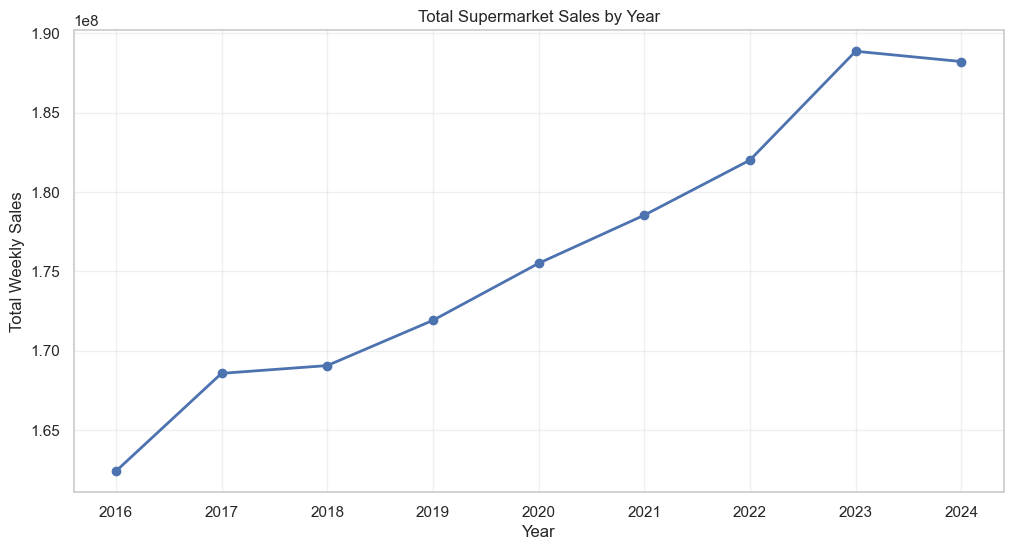

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Total Supermarket Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Weekly Sales")
plt.xticks(yearly_sales.index)
plt.grid(True, alpha=0.3)

plt.show()

In [8]:
store_sales = (
    df.groupby("Store")["Weekly_Sales"]
      .sum()
      .sort_values(ascending=False)
)

print(store_sales)

Store
Bhat-Bhateni          104362025.90
CityCenter KTM         94066658.03
Kathmandu Mart         85008170.86
Himalayan Hyper        80771089.73
Pokhara BigMart        78358096.03
Saleways Nepal         75688882.17
Lalitpur Market        65297576.74
Pokhara Plaza          62476754.77
Hetauda Hyper          61408165.23
KK Mart                60077675.36
Butwal SuperMart       58859003.66
Midland Mart           58296450.90
Biratnagar Mart        57414299.16
Chitwan SuperCenter    56740390.96
Itahari Center         55976072.17
Bhairahawa Mall        55524615.41
Dharan Plaza           54860108.88
Northern Market        54794813.24
Eastern Plaza          54275275.38
Nepalgunj Market       53507708.28
Janakpur Mart          52260015.64
Western Super          51954082.60
Township Mart          51610890.37
Birgunj Mart           50907441.33
Southern Bazaar        50652104.14
Name: Weekly_Sales, dtype: float64


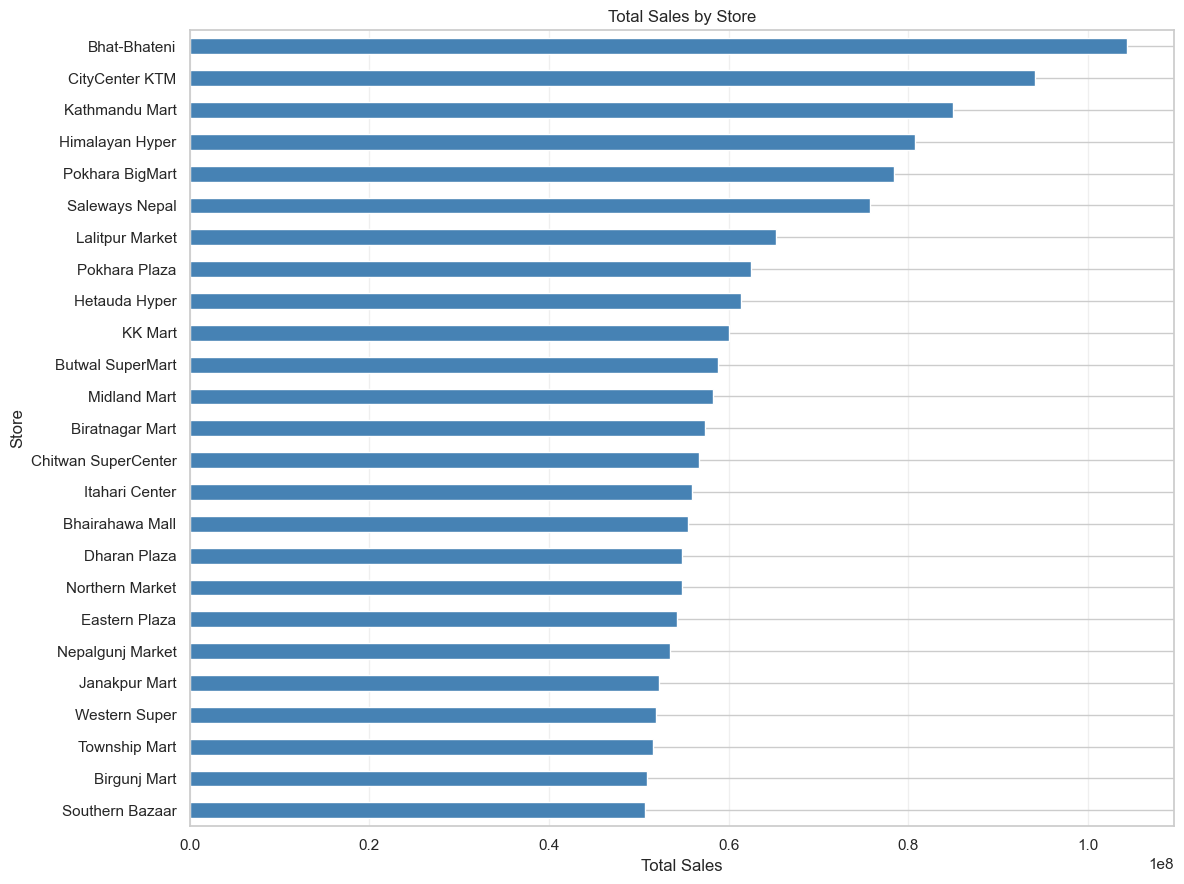

In [9]:
plt.figure(figsize=(12, 9))

store_sales.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Total Sales by Store")
plt.xlabel("Total Sales")
plt.ylabel("Store")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [10]:
dept_sales = (
    df.groupby("Dept")["Weekly_Sales"]
      .sum()
      .sort_values(ascending=False)
)

print(dept_sales)

Dept
Household Care         92883684.77
Bakery                 91312095.19
Meat                   89191158.89
Pharmacy               87615759.16
Frozen Foods           85869956.22
Dairy                  84349319.53
Beverages              83806312.47
Beauty                 82206176.44
Home & Kitchen         80777827.81
Fruits                 79121927.02
Clothing               78341872.76
Vegetables             77419781.07
Stationery             75376100.85
Footwear               74392918.46
Auto Accessories       72874627.06
Hardware               72379386.87
Electronics            71581470.77
Grocery                70976025.00
Toys                   68736925.55
Mobile & Accessories   65935041.05
Name: Weekly_Sales, dtype: float64


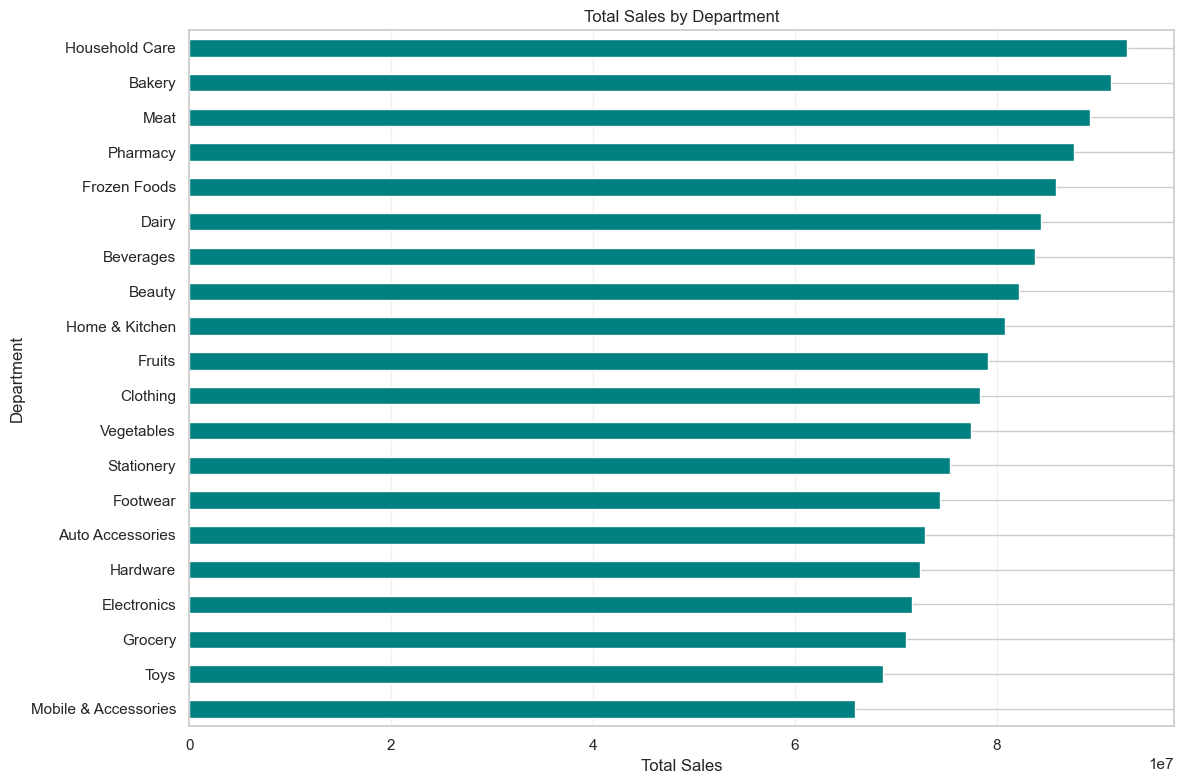

In [11]:
plt.figure(figsize=(12, 8))

dept_sales.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Total Sales by Department")
plt.xlabel("Total Sales")
plt.ylabel("Department")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [12]:
holiday_sales = (
    df.groupby("IsHoliday")["Weekly_Sales"]
      .agg(["mean", "median", "sum", "count"])
)

print(holiday_sales)

             mean  median           sum   count
IsHoliday                                      
False     6375.12 5969.34 1122021890.72  176000
True      7849.60 7391.16  463126476.22   59000


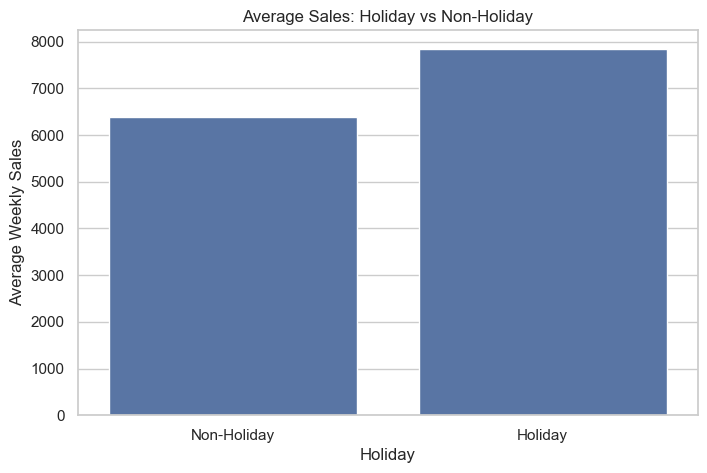

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=holiday_sales.index,
    y=holiday_sales["mean"]
)

plt.title("Average Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday")
plt.ylabel("Average Weekly Sales")

plt.xticks(
    [0, 1],
    ["Non-Holiday", "Holiday"]
)

plt.show()

In [14]:
holiday_name_sales = (
    df[df["IsHoliday"] == True]
    .groupby("Holiday_Name")["Weekly_Sales"]
    .agg(["mean", "median", "sum", "count"])
    .sort_values("mean", ascending=False)
)

print(holiday_name_sales)

                                mean  median         sum  count
Holiday_Name                                                   
Holi                         9305.91 8700.28 41876614.75   4500
Tihar                        9235.23 8635.83 41558512.67   4500
Valentine's Day              9013.04 8401.88 40558697.52   4500
Nepali New Year              8841.24 8236.78 39785563.45   4500
Dashain                      8792.90 8251.42 39568055.00   4500
Christmas                    8153.74 7649.53 36691845.40   4500
Labour Day                   8030.43 7505.26 36136928.33   4500
New Year (Jan 1)             7854.91 7337.93 35347115.10   4500
Buddha Jayanti               7549.63 7061.24 33973351.39   4500
Eid al-Fitr                  7176.87 6739.10 32295913.00   4500
Eid al-Adha                  6649.92 6232.35  3324960.97    500
Constitution Day;Eid al-Adha 6449.67 6048.16 25798675.72   4000
Teej                         6086.26 5699.18 27388167.35   4500
Constitution Day             6039.77 569

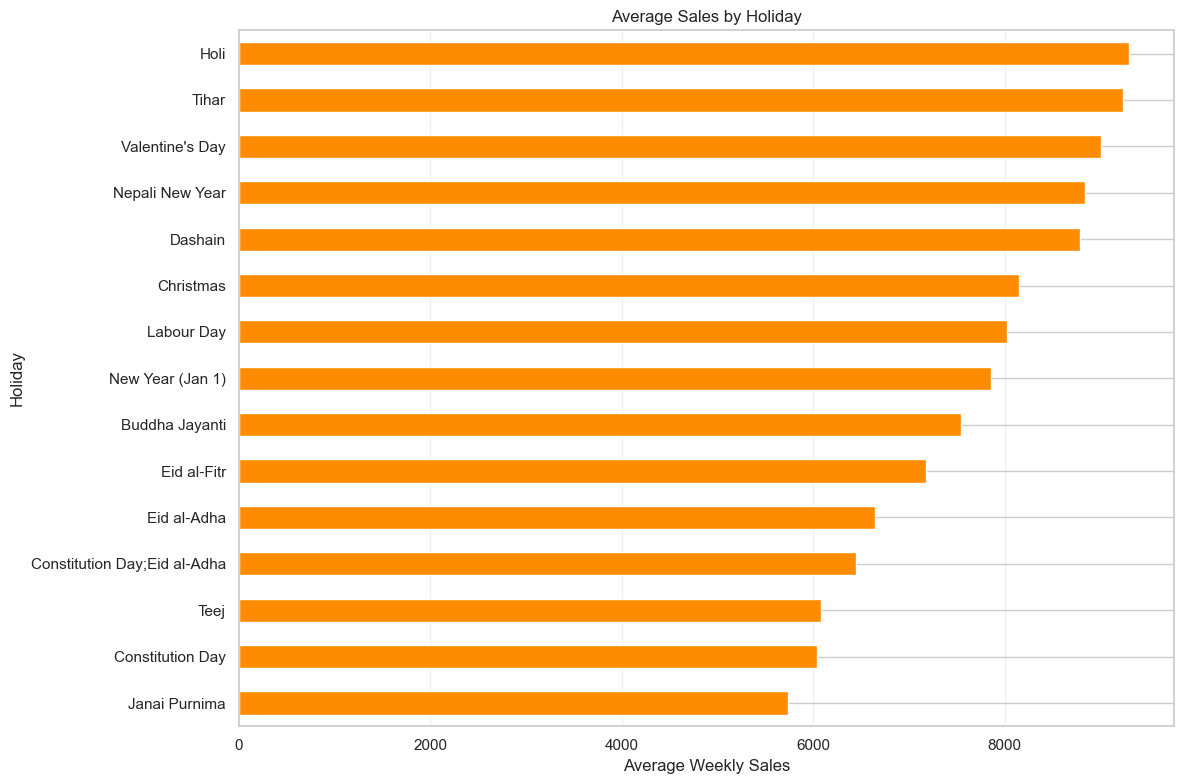

In [15]:
plt.figure(figsize=(12, 8))

holiday_name_sales["mean"].sort_values().plot(
    kind="barh",
    color="darkorange"
)

plt.title("Average Sales by Holiday")
plt.xlabel("Average Weekly Sales")
plt.ylabel("Holiday")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [16]:
store_size_sales = (
    df.groupby("Store")
      .agg(
          Store_Size=("Store_Size", "first"),
          Total_Sales=("Weekly_Sales", "sum")
      )
      .sort_values("Total_Sales", ascending=False)
)

print(store_size_sales)

                     Store_Size  Total_Sales
Store                                       
Bhat-Bhateni               5000 104362025.90
CityCenter KTM             4200  94066658.03
Kathmandu Mart             3500  85008170.86
Himalayan Hyper            3200  80771089.73
Pokhara BigMart            3000  78358096.03
Saleways Nepal             2800  75688882.17
Lalitpur Market            2000  65297576.74
Pokhara Plaza              1800  62476754.77
Hetauda Hyper              1700  61408165.23
KK Mart                    1600  60077675.36
Butwal SuperMart           1500  58859003.66
Midland Mart               1450  58296450.90
Biratnagar Mart            1400  57414299.16
Chitwan SuperCenter        1350  56740390.96
Itahari Center             1300  55976072.17
Bhairahawa Mall            1250  55524615.41
Dharan Plaza               1200  54860108.88
Northern Market            1200  54794813.24
Eastern Plaza              1150  54275275.38
Nepalgunj Market           1100  53507708.28
Janakpur M

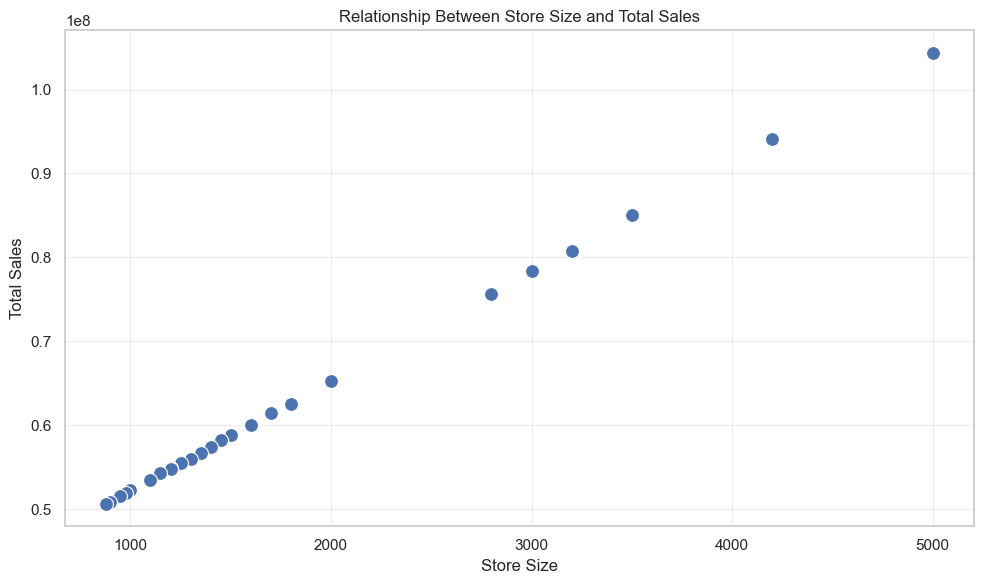

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=store_size_sales,
    x="Store_Size",
    y="Total_Sales",
    s=100
)

plt.title("Relationship Between Store Size and Total Sales")
plt.xlabel("Store Size")
plt.ylabel("Total Sales")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [18]:
correlation = store_size_sales["Store_Size"].corr(
    store_size_sales["Total_Sales"]
)

print("Correlation:", round(correlation, 4))

Correlation: 1.0


In [19]:
print("Exact correlation:", store_size_sales["Store_Size"].corr(
    store_size_sales["Total_Sales"]
))

Exact correlation: 0.9999802461179578


In [20]:
store_size_sales["Sales_Per_Size_Unit"] = (
    store_size_sales["Total_Sales"] /
    store_size_sales["Store_Size"]
)

print(
    store_size_sales[
        ["Store_Size", "Total_Sales", "Sales_Per_Size_Unit"]
    ].sort_values("Sales_Per_Size_Unit", ascending=False)
)

                     Store_Size  Total_Sales  Sales_Per_Size_Unit
Store                                                            
Southern Bazaar             880  50652104.14             57559.21
Birgunj Mart                900  50907441.33             56563.82
Township Mart               950  51610890.37             54327.25
Western Super               980  51954082.60             53014.37
Janakpur Mart              1000  52260015.64             52260.02
Nepalgunj Market           1100  53507708.28             48643.37
Eastern Plaza              1150  54275275.38             47195.89
Dharan Plaza               1200  54860108.88             45716.76
Northern Market            1200  54794813.24             45662.34
Bhairahawa Mall            1250  55524615.41             44419.69
Itahari Center             1300  55976072.17             43058.52
Chitwan SuperCenter        1350  56740390.96             42029.92
Biratnagar Mart            1400  57414299.16             41010.21
Midland Ma

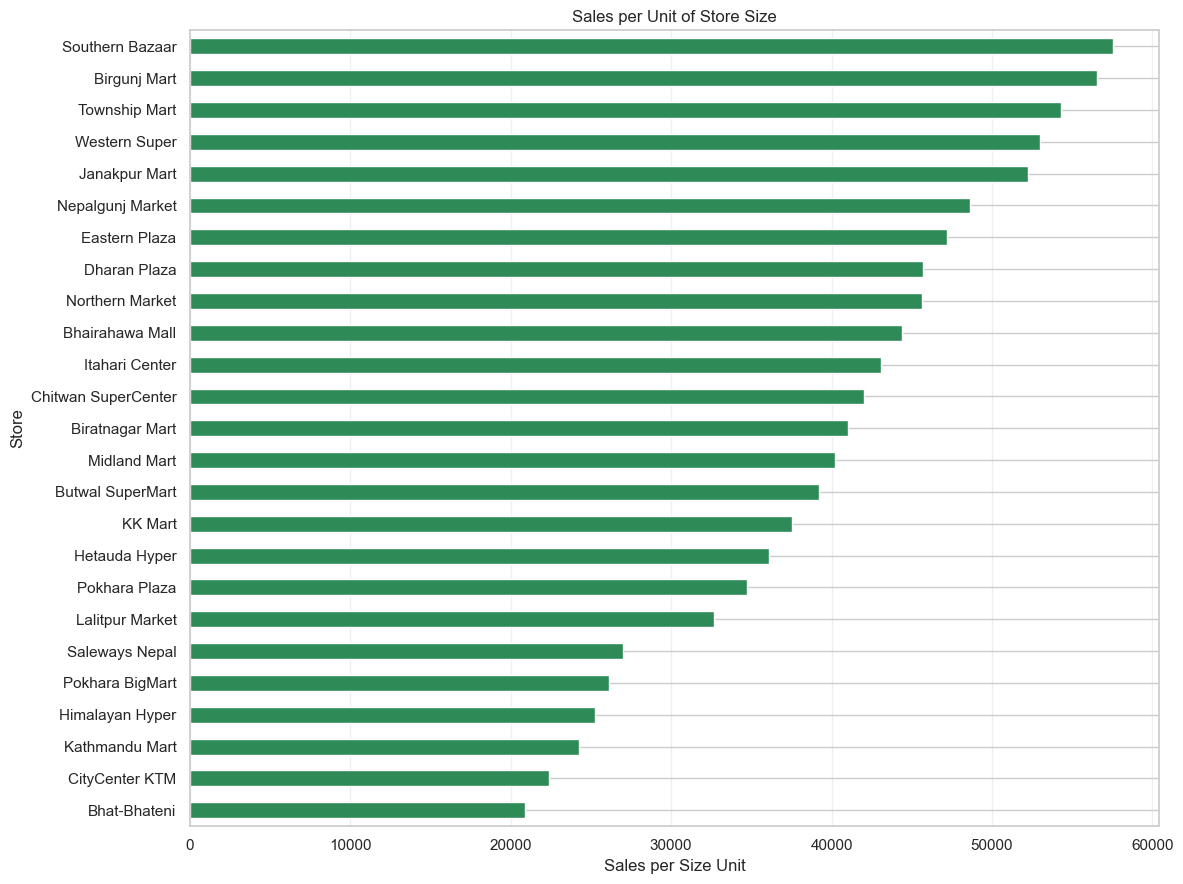

In [21]:
plt.figure(figsize=(12, 9))

store_size_sales["Sales_Per_Size_Unit"].sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Sales per Unit of Store Size")
plt.xlabel("Sales per Size Unit")
plt.ylabel("Store")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [22]:
store_type_sales = (
    df.groupby("Store_Type")["Weekly_Sales"]
      .agg(["mean", "median", "sum", "count"])
      .sort_values("mean", ascending=False)
)

print(store_type_sales)

              mean  median          sum  count
Store_Type                                    
A          9188.92 8859.19 518254922.72  56400
B          6271.78 6077.68 530592514.78  84600
C          5705.33 5529.78 536300929.44  94000


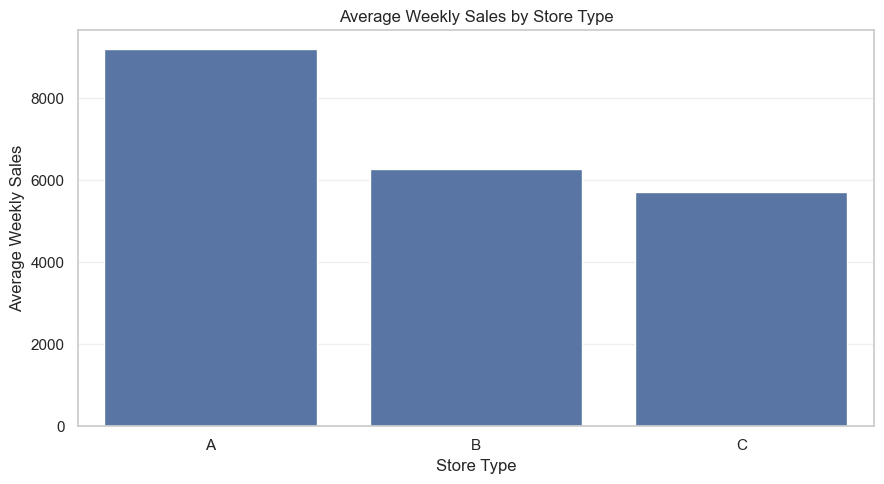

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Store_Type",
    y="Weekly_Sales",
    estimator="mean",
    errorbar=None
)

plt.title("Average Weekly Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Weekly Sales")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
dept_store_type = (
    df.groupby(["Dept", "Store_Type"])["Weekly_Sales"]
      .mean()
      .unstack()
)

print(dept_store_type.round(2))

Store_Type                  A       B       C
Dept                                         
Auto Accessories      8436.56 5764.93 5254.87
Bakery               10588.03 7236.05 6562.84
Beauty                9504.78 6493.25 5943.88
Beverages             9716.13 6633.38 6031.41
Clothing              9056.37 6192.94 5661.02
Dairy                 9784.61 6682.13 6061.98
Electronics           8320.09 5662.27 5142.01
Footwear              8613.50 5890.83 5358.44
Frozen Foods          9941.36 6809.45 6176.89
Fruits                9187.97 6258.59 5688.94
Grocery               8221.94 5624.44 5106.12
Hardware              8401.94 5731.96 5199.94
Home & Kitchen        9389.08 6391.67 5800.82
Household Care       10796.21 7339.89 6678.86
Meat                 10344.31 7047.23 6427.75
Mobile & Accessories  7646.46 5217.86 4744.78
Pharmacy             10163.88 6930.71 6305.68
Stationery            8736.05 5968.31 5424.36
Toys                  7973.55 5432.37 4951.62
Vegetables            8955.55 6127

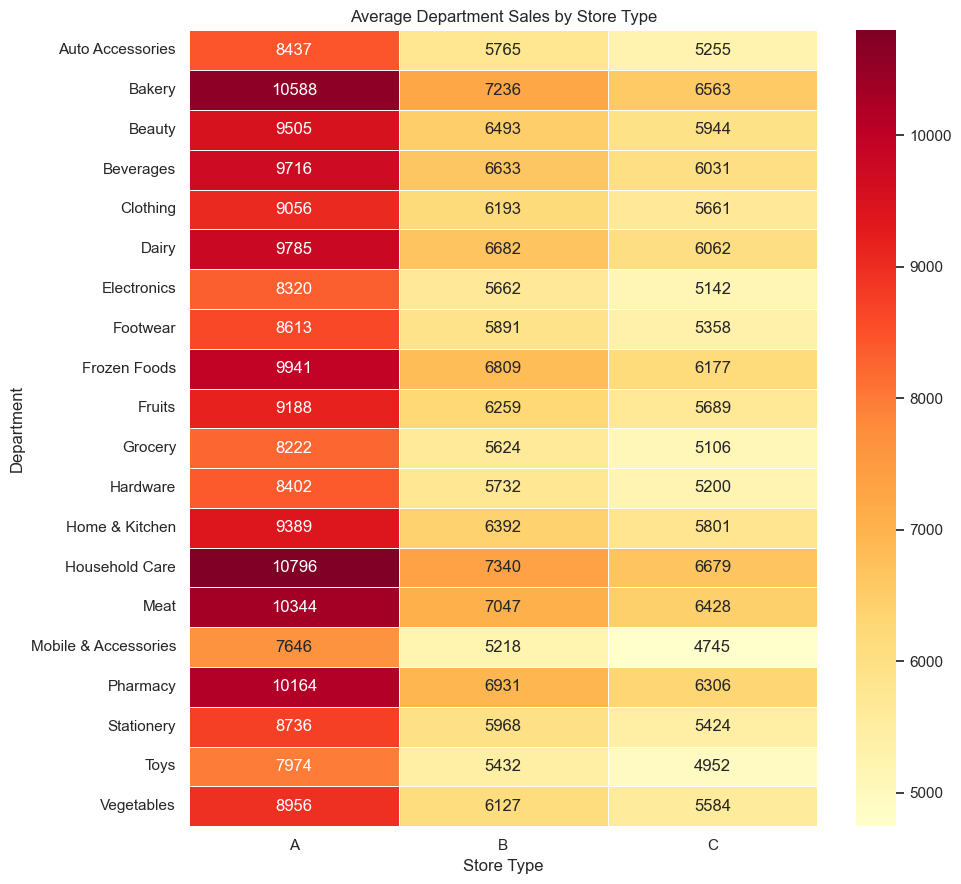

In [25]:
plt.figure(figsize=(10, 9))

sns.heatmap(
    dept_store_type,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Average Department Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

In [26]:
external_correlations = df[
    [
        "Weekly_Sales",
        "Temperature",
        "Fuel_Price",
        "CPI",
        "Unemployment"
    ]
].corr()

print(external_correlations["Weekly_Sales"].sort_values(ascending=False))

Weekly_Sales    1.00
CPI             0.14
Fuel_Price      0.14
Unemployment    0.07
Temperature    -0.27
Name: Weekly_Sales, dtype: float64


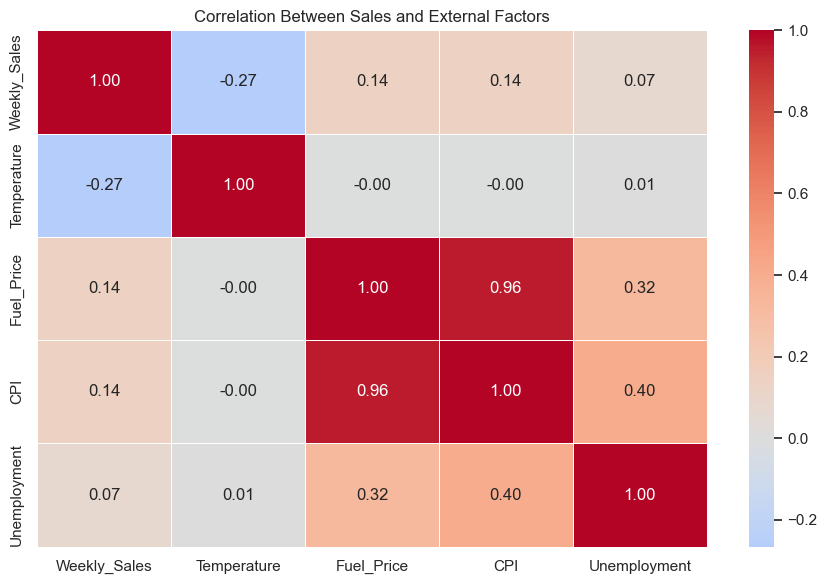

In [27]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    external_correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Sales and External Factors")
plt.tight_layout()
plt.show()

In [28]:
monthly_sales = (
    df.groupby(df["Date"].dt.month)["Weekly_Sales"]
      .mean()
)

print(monthly_sales)

Date
1    7290.68
2    7892.64
3    8036.34
4    7749.78
5    7181.95
6    6359.38
7    5449.45
8    5319.37
9    5718.61
10   6276.08
11   6882.01
12   6880.67
Name: Weekly_Sales, dtype: float64


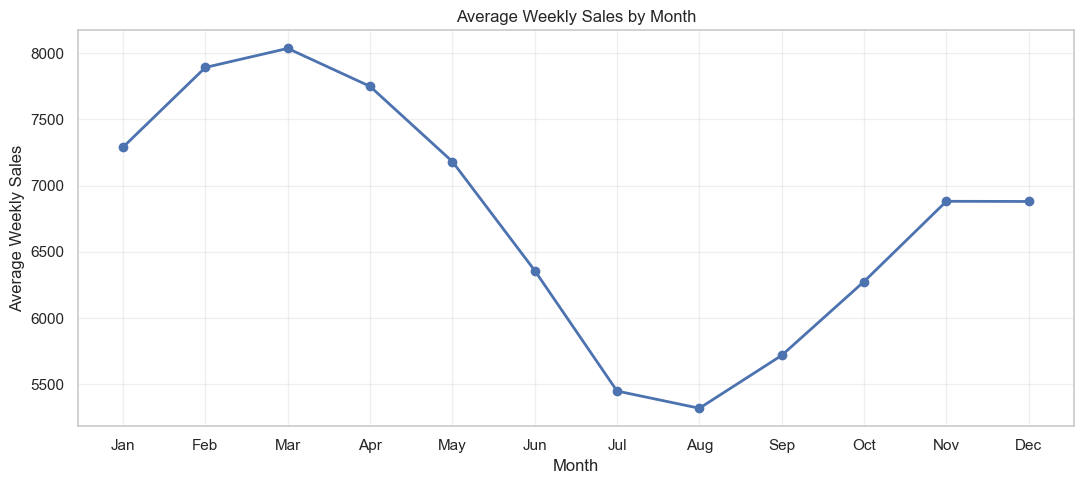

In [29]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Average Weekly Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
yearly_sales = df.groupby(
    df["Date"].dt.year
)["Weekly_Sales"].sum()

yearly_growth = yearly_sales.pct_change() * 100

yearly_growth = yearly_growth.round(2)

print(yearly_growth)

Date
2016     NaN
2017    3.80
2018    0.29
2019    1.69
2020    2.09
2021    1.73
2022    1.94
2023    3.77
2024   -0.34
Name: Weekly_Sales, dtype: float64


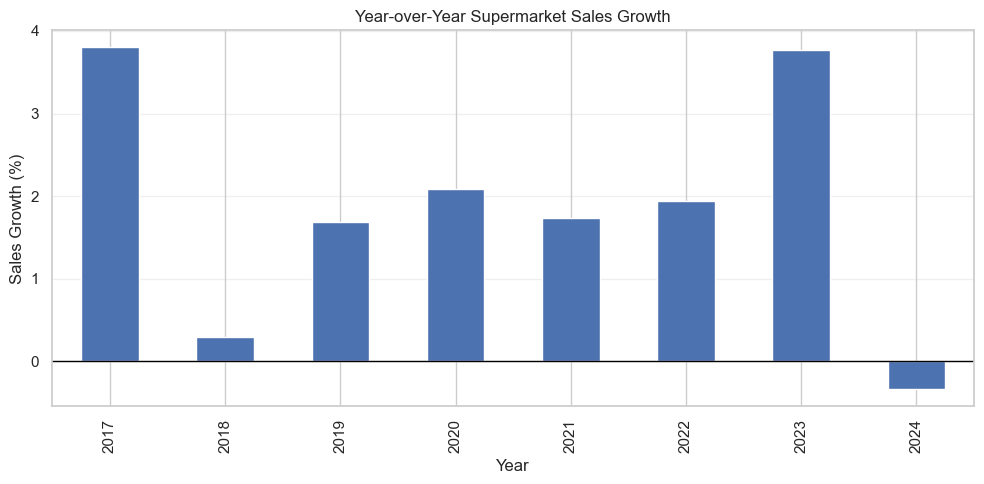

In [31]:
plt.figure(figsize=(10, 5))

yearly_growth.dropna().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Year-over-Year Supermarket Sales Growth")
plt.xlabel("Year")
plt.ylabel("Sales Growth (%)")

plt.axhline(y=0, color="black", linewidth=1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Exploratory Data Analysis – Key Findings

## 1. Overall Sales Performance
- Total recorded sales: approximately 1.585 billion.
- Average sales per record: 6,745.31.
- Median sales per record: 6,295.75.
- Sales distribution is right-skewed, with some unusually high observations.

## 2. Yearly Sales Trends
- Overall sales generally increased between 2016 and 2024.
- 2023 recorded the highest annual total.
- 2024 experienced a small decline compared with 2023.

## 3. Store Performance
- Bhat-Bhateni recorded the highest total sales.
- Southern Bazaar recorded the lowest total sales.
- Larger stores generally generated higher total sales.

## 4. Department Performance
- Household Care generated the highest total sales.
- Mobile & Accessories generated the lowest total sales.

## 5. Holiday Analysis
- Average sales were higher during holiday weeks.
- Holi recorded the highest average sales among individual holiday categories.
- Tihar and Valentine's Day also recorded high average sales.

## 6. Store Size Analysis
- Store size and total sales had an almost perfect positive correlation (0.99998).
- Smaller stores generated higher sales per unit of store size.
- This suggests a distinction between total sales and sales relative to store size.

## 7. Store Type Analysis
- Store Type A had the highest average sales.
- Store Type C had the highest total sales.
- Store Type A consistently outperformed B and C across all 20 departments in average sales.

## 8. External Factors
- Temperature had a weak negative correlation with sales (-0.27).
- CPI and Fuel Price each had a weak positive correlation (0.14).
- Unemployment had a very weak positive correlation (0.07).

## 9. Monthly Sales Patterns
- March recorded the highest average sales.
- August recorded the lowest average sales.
- Sales generally declined between March and August before recovering.

## 10. Year-over-Year Growth
- 2017 recorded the highest growth (3.80%).
- 2023 recorded strong growth (3.77%).
- 2024 recorded a small decline (-0.34%).

## Conclusion
The exploratory analysis identified differences in sales performance across stores, departments, store types, holidays and months.

Store size, store type and holiday periods showed particularly interesting patterns.

These findings are based on a synthetic educational dataset and should not be interpreted as actual Nepalese retail market statistics.
